In [2]:
## Imports

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

In [3]:
## Create Sample Inventory Dataset

inventory_df = pd.DataFrame({

    "Item":[
        "Item A",
        "Item B",
        "Item C",
        "Item D",
        "Item E"
    ],

    "Inventory":[
        1500,
        800,
        2000,
        400,
        1200
    ],

    "Weekly_Demand":[
        200,
        150,
        100,
        120,
        250
    ],

    "Unit_Cost":[
        10,
        20,
        15,
        25,
        12
    ]

})

display(inventory_df)

,Item,Inventory,Weekly_Demand,Unit_Cost
0,Item A,1500,200,10
1,Item B,800,150,20
2,Item C,2000,100,15
3,Item D,400,120,25
4,Item E,1200,250,12


In [4]:
## Calculate Inventory Value

inventory_df["Inventory_Value"] = (

    inventory_df["Inventory"]

    * inventory_df["Unit_Cost"]

)

display(inventory_df)

,Item,Inventory,Weekly_Demand,Unit_Cost,Inventory_Value
0,Item A,1500,200,10,15000
1,Item B,800,150,20,16000
2,Item C,2000,100,15,30000
3,Item D,400,120,25,10000
4,Item E,1200,250,12,14400


In [5]:
## Calculate Weeks of Supply

inventory_df["Weeks_of_Supply"] = (

    inventory_df["Inventory"]

    / inventory_df["Weekly_Demand"]

)

display(inventory_df)

,Item,Inventory,Weekly_Demand,Unit_Cost,Inventory_Value,Weeks_of_Supply
0,Item A,1500,200,10,15000,7.500000
1,Item B,800,150,20,16000,5.333333
2,Item C,2000,100,15,30000,20.000000
3,Item D,400,120,25,10000,3.333333
4,Item E,1200,250,12,14400,4.800000


In [6]:
## Excess Inventory Identification

inventory_df["Excess_Inventory"] = np.where(

    inventory_df["Weeks_of_Supply"] > 8,

    "Yes",

    "No"

)

display(inventory_df)

,Item,Inventory,Weekly_Demand,Unit_Cost,Inventory_Value,Weeks_of_Supply,Excess_Inventory
0,Item A,1500,200,10,15000,7.500000,No
1,Item B,800,150,20,16000,5.333333,No
2,Item C,2000,100,15,30000,20.000000,Yes
3,Item D,400,120,25,10000,3.333333,No
4,Item E,1200,250,12,14400,4.800000,No


In [7]:
## Inventory Health Classification

inventory_df["Health"] = np.where(

    inventory_df["Weeks_of_Supply"] > 8,

    "Overstock",

    np.where(

        inventory_df["Weeks_of_Supply"] < 2,

        "Understock",

        "Balanced"

    )

)

display(inventory_df)

,Item,Inventory,Weekly_Demand,Unit_Cost,Inventory_Value,Weeks_of_Supply,Excess_Inventory,Health
0,Item A,1500,200,10,15000,7.500000,No,Balanced
1,Item B,800,150,20,16000,5.333333,No,Balanced
2,Item C,2000,100,15,30000,20.000000,Yes,Overstock
3,Item D,400,120,25,10000,3.333333,No,Balanced
4,Item E,1200,250,12,14400,4.800000,No,Balanced


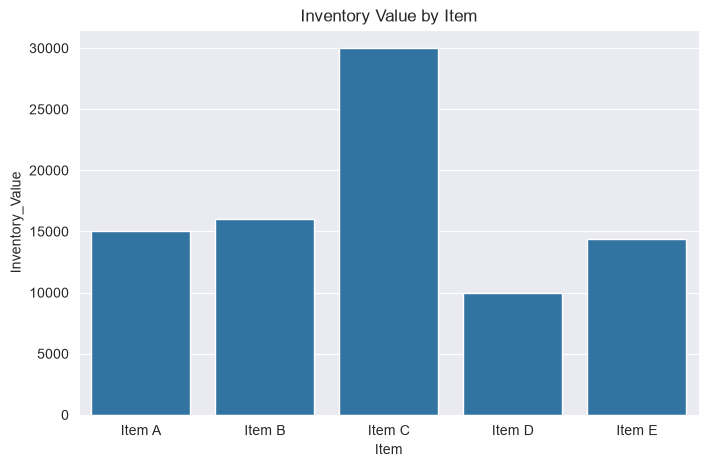

In [8]:
## Inventory Value by Item

plt.figure(figsize=(8,5))

sns.barplot(
    data=inventory_df,
    x="Item",
    y="Inventory_Value"
)

plt.title("Inventory Value by Item")

plt.show()

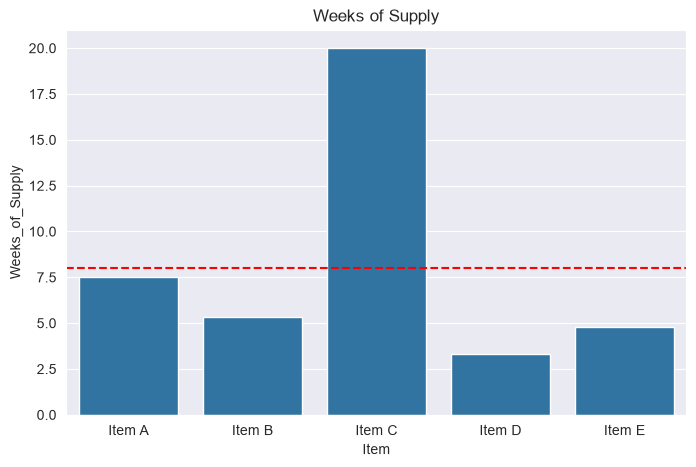

In [9]:
## Weeks of Supply Chart

plt.figure(figsize=(8,5))

sns.barplot(
    data=inventory_df,
    x="Item",
    y="Weeks_of_Supply"
)

plt.axhline(
    y=8,
    color="red",
    linestyle="--"
)

plt.title("Weeks of Supply")

plt.show()

In [10]:
## Total Inventory Investment

total_inventory = (

    inventory_df["Inventory_Value"]

    .sum()

)

print(
    f"Total Inventory Value: "
    f"${total_inventory:,.0f}"
)

Total Inventory Value: $85,400


In [11]:
## Calculate Optimization Opportunity

inventory_df["Potential_Reduction"] = np.where(

    inventory_df["Health"] == "Overstock",

    inventory_df["Inventory_Value"] * 0.20,

    0

)

display(inventory_df)

,Item,Inventory,Weekly_Demand,Unit_Cost,Inventory_Value,Weeks_of_Supply,Excess_Inventory,Health,Potential_Reduction
0,Item A,1500,200,10,15000,7.500000,No,Balanced,0.0
1,Item B,800,150,20,16000,5.333333,No,Balanced,0.0
2,Item C,2000,100,15,30000,20.000000,Yes,Overstock,6000.0
3,Item D,400,120,25,10000,3.333333,No,Balanced,0.0
4,Item E,1200,250,12,14400,4.800000,No,Balanced,0.0


In [12]:
## Working Capital Savings

working_capital = (

    inventory_df["Potential_Reduction"]

    .sum()

)

print(

    f"Potential Working Capital Savings: "

    f"${working_capital:,.0f}"

)

Potential Working Capital Savings: $6,000


In [13]:
## Reorder Point Calculation

inventory_df["Reorder_Point"] = (

    inventory_df["Weekly_Demand"]

    * 2

)

display(inventory_df)

,Item,Inventory,Weekly_Demand,Unit_Cost,Inventory_Value,Weeks_of_Supply,Excess_Inventory,Health,Potential_Reduction,Reorder_Point
0,Item A,1500,200,10,15000,7.500000,No,Balanced,0.0,400
1,Item B,800,150,20,16000,5.333333,No,Balanced,0.0,300
2,Item C,2000,100,15,30000,20.000000,Yes,Overstock,6000.0,200
3,Item D,400,120,25,10000,3.333333,No,Balanced,0.0,240
4,Item E,1200,250,12,14400,4.800000,No,Balanced,0.0,500


In [14]:
## Recommended Actions

inventory_df["Recommendation"] = np.where(

    inventory_df["Health"] == "Overstock",

    "Reduce Orders",

    np.where(

        inventory_df["Health"] == "Understock",

        "Increase Orders",

        "Maintain Current Level"

    )

)

display(inventory_df)

,Item,Inventory,Weekly_Demand,Unit_Cost,Inventory_Value,Weeks_of_Supply,Excess_Inventory,Health,Potential_Reduction,Reorder_Point,Recommendation
0,Item A,1500,200,10,15000,7.500000,No,Balanced,0.0,400,Maintain Current Level
1,Item B,800,150,20,16000,5.333333,No,Balanced,0.0,300,Maintain Current Level
2,Item C,2000,100,15,30000,20.000000,Yes,Overstock,6000.0,200,Reduce Orders
3,Item D,400,120,25,10000,3.333333,No,Balanced,0.0,240,Maintain Current Level
4,Item E,1200,250,12,14400,4.800000,No,Balanced,0.0,500,Maintain Current Level


In [15]:
## Optimization Dashboard

dashboard = inventory_df[[

    "Item",

    "Inventory",

    "Weeks_of_Supply",

    "Inventory_Value",

    "Health",

    "Recommendation"

]]

display(dashboard)

,Item,Inventory,Weeks_of_Supply,Inventory_Value,Health,Recommendation
0,Item A,1500,7.500000,15000,Balanced,Maintain Current Level
1,Item B,800,5.333333,16000,Balanced,Maintain Current Level
2,Item C,2000,20.000000,30000,Overstock,Reduce Orders
3,Item D,400,3.333333,10000,Balanced,Maintain Current Level
4,Item E,1200,4.800000,14400,Balanced,Maintain Current Level


In [16]:
## Executive Summary

print("""

EXECUTIVE SUMMARY

Several items exhibit excess inventory
positions.

Reducing inventory on overstocked items
could free working capital while
maintaining service levels.

Recommended actions focus on inventory
rebalancing and replenishment optimization.

""")




EXECUTIVE SUMMARY

Several items exhibit excess inventory
positions.

Reducing inventory on overstocked items
could free working capital while
maintaining service levels.

Recommended actions focus on inventory
rebalancing and replenishment optimization.




In [17]:
## Financial Impact

print(

    f"Current Inventory Investment: "

    f"${inventory_df['Inventory_Value'].sum():,.0f}"

)

print(

    f"Potential Savings: "

    f"${inventory_df['Potential_Reduction'].sum():,.0f}"

)

Current Inventory Investment: $85,400
Potential Savings: $6,000


In [18]:
## Talking Points

print("""

WALMART INVENTORY FLOW INSIGHTS

1. Inventory should support demand
   without creating excess investment.

2. Weeks of Supply identifies
   inventory imbalance.

3. Working capital improves when
   overstock is reduced.

4. Reorder points improve
   replenishment decisions.

5. Inventory optimization balances
   customer service and profitability.

""")



WALMART INVENTORY FLOW INSIGHTS

1. Inventory should support demand
   without creating excess investment.

2. Weeks of Supply identifies
   inventory imbalance.

3. Working capital improves when
   overstock is reduced.

4. Reorder points improve
   replenishment decisions.

5. Inventory optimization balances
   customer service and profitability.


